# Module 5: The transformer block: residuals, RMSNorm, SwiGLU
Companion to `docs/05_transformer_block.html`. We write LayerNorm, RMSNorm, the GELU MLP and SwiGLU from scratch and check them against
PyTorch and Hugging Face, rebuild a GPT-2 block from its raw weights, look inside GPT-2's residual stream, show why deep models need
residuals and pre-norm, and train tiny character models with and without each piece.
Runs on a laptop CPU in about 15 minutes (sections 6 and 7 train models; the GPT-2 download is the only network step besides the text file).

In [1]:
import os, math, time, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)

## 0. Model code
Pasted from `tools/module05/block_core.py` so this notebook is standalone. `Block` has switches for every choice this module discusses:
the norm (`'ln'`, `'rms'`, `None`), its placement (`'pre'`, `'post'`), the feed-forward network (`'gelu'`, `'swiglu'`, `None`) and whether the residual `x +` is there.

In [2]:
# --- shared by data.py, figs.py and the notebook (mknb.py pastes this file into the notebook) ---
import math, torch, torch.nn as nn, torch.nn.functional as F

def attention(q, k, v):
    """Causal scaled dot-product attention (Module 4). q, k, v: (..., T, d)."""
    T = q.shape[-2]
    s = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    s = s.masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), float("-inf"))
    return F.softmax(s, dim=-1) @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, d, h, bias=True):
        super().__init__()
        self.h = h
        self.qkv = nn.Linear(d, 3 * d, bias=bias)
        self.proj = nn.Linear(d, d, bias=bias)
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = (z.view(B, T, self.h, D // self.h).transpose(1, 2) for z in self.qkv(x).split(D, -1))
        return self.proj(attention(q, k, v).transpose(1, 2).reshape(B, T, D))

class LayerNorm(nn.Module):
    """Ba et al. 2016: subtract the mean, divide by the standard deviation, then a learned gain and bias."""
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.eps, self.weight, self.bias = eps, nn.Parameter(torch.ones(d)), nn.Parameter(torch.zeros(d))
    def forward(self, x):
        mu = x.mean(-1, keepdim=True)
        var = ((x - mu) ** 2).mean(-1, keepdim=True)              # biased variance, as in PyTorch
        return (x - mu) / torch.sqrt(var + self.eps) * self.weight + self.bias

class RMSNorm(nn.Module):
    """Zhang & Sennrich 2019: no mean subtraction, no bias; divide by the root mean square, then a learned gain."""
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps, self.weight = eps, nn.Parameter(torch.ones(d))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

class MLP(nn.Module):
    """The original position-wise feed-forward network: d -> 4d -> d with a GELU (GPT-2 uses the tanh approximation)."""
    def __init__(self, d, hidden=None, bias=True, approximate="tanh"):
        super().__init__()
        hidden = hidden or 4 * d
        self.fc, self.proj, self.approximate = nn.Linear(d, hidden, bias=bias), nn.Linear(hidden, d, bias=bias), approximate
    def forward(self, x):
        return self.proj(F.gelu(self.fc(x), approximate=self.approximate))

class SwiGLU(nn.Module):
    """Shazeer 2020: (Swish(x W_gate) * x W_up) W_down, no biases. hidden = 2/3 * 4d keeps the parameter count of the 4d MLP."""
    def __init__(self, d, hidden=None):
        super().__init__()
        hidden = hidden or int(2 * 4 * d / 3)
        self.gate, self.up, self.down = nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False), nn.Linear(hidden, d, bias=False)
    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))     # silu(z) = z * sigmoid(z) = Swish with beta = 1

NORMS = {"ln": LayerNorm, "rms": RMSNorm, None: lambda d: nn.Identity()}

class Block(nn.Module):
    """One transformer block. norm: 'ln' | 'rms' | None;  place: 'pre' | 'post';  ffn: 'gelu' | 'swiglu' | None;  residual: bool."""
    def __init__(self, d, h, norm="rms", place="pre", ffn="swiglu", residual=True):
        super().__init__()
        self.place, self.residual = place, residual
        self.n1, self.att = NORMS[norm](d), MultiHeadAttention(d, h)
        self.ffn = {"gelu": lambda: MLP(d), "swiglu": lambda: SwiGLU(d), None: lambda: None}[ffn]()
        self.n2 = NORMS[norm](d) if self.ffn is not None else None
    def forward(self, x):
        r = 1.0 if self.residual else 0.0                        # residual=False: same block, the "x +" removed
        if self.place == "pre":                                  # x + f(norm(x)): the stream itself is never normalised
            x = r * x + self.att(self.n1(x))
            if self.ffn is not None: x = r * x + self.ffn(self.n2(x))
        else:                                                    # post-LN (Vaswani 2017): norm(x + f(x))
            x = self.n1(r * x + self.att(x))
            if self.ffn is not None: x = self.n2(r * x + self.ffn(x))
        return x

class GPT(nn.Module):
    """Character LM: token + learned position embeddings, L blocks, a final norm (pre-norm models only), linear head."""
    def __init__(self, V, T, d=64, h=4, L=2, **blk):
        super().__init__()
        self.T = T
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(T, d)
        self.blocks = nn.ModuleList(Block(d, h, **blk) for _ in range(L))
        pre_norm = blk.get("place", "pre") == "pre" and blk.get("norm", "rms") is not None
        self.nf = NORMS[blk.get("norm", "rms")](d) if pre_norm else nn.Identity()
        self.out = nn.Linear(d, V)
    def forward(self, x):
        z = self.tok(x) + self.pos(torch.arange(x.shape[1]))
        for b in self.blocks: z = b(z)
        return self.out(self.nf(z))

def batches(ids, T, bs, g):
    ids = torch.as_tensor(ids, dtype=torch.long)
    i = torch.randint(0, len(ids) - T - 1, (bs,), generator=g)
    idx = i[:, None] + torch.arange(T + 1)[None, :]
    return ids[idx][:, :-1], ids[idx][:, 1:]

def train(model, ids, steps=3000, bs=64, lr=3e-3, warmup=0, seed=0, log_every=50):
    """Adam, optional linear warmup, then cosine decay. Returns the training loss averaged over each log_every steps (nan once diverged)."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lr_at = lambda s: lr * (s + 1) / warmup if s < warmup else lr * 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, steps - warmup)))
    hist, acc = [], 0.0
    for s in range(steps):
        for gr in opt.param_groups: gr["lr"] = lr_at(s)
        x, y = batches(ids, model.T, bs, g)
        loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        if not torch.isfinite(loss):
            hist += [float("nan")] * ((steps - s) // log_every); break
        opt.zero_grad(); loss.backward(); opt.step()
        acc += loss.item()
        if (s + 1) % log_every == 0: hist.append(acc / log_every); acc = 0.0
    return hist

@torch.no_grad()
def evaluate(model, ids, min_pos=8):
    """Mean loss over non-overlapping windows, scoring positions >= min_pos (same protocol as Module 4)."""
    ids = torch.as_tensor(ids, dtype=torch.long); T = model.T; n = (len(ids) - 1) // T
    x = ids[: n * T].view(n, T); y = ids[1 : n * T + 1].view(n, T)
    tot = 0.0
    for i in range(0, n, 256):
        lg = model(x[i:i+256])[:, min_pos:]
        tot += float(F.cross_entropy(lg.flatten(0, 1), y[i:i+256, min_pos:].flatten(), reduction="sum"))
    return tot / (n * (T - min_pos))

def grad_norm_per_block(model, ids, bs=64, seed=0):
    """One backward pass at the current weights; the gradient norm of each block's parameters."""
    x, y = batches(ids, model.T, bs, torch.Generator().manual_seed(seed))
    model.zero_grad(); F.cross_entropy(model(x).flatten(0, 1), y.flatten()).backward()
    return [math.sqrt(sum(float(p.grad.pow(2).sum()) for p in b.parameters())) for b in model.blocks]

@torch.no_grad()
def token_similarity_per_block(model, ids, bs=64, seed=0):
    """Mean cosine similarity between the vectors of different positions of a sequence, after each block (rank collapse if it goes to 1)."""
    x, _ = batches(ids, model.T, bs, torch.Generator().manual_seed(seed))
    z = model.tok(x) + model.pos(torch.arange(x.shape[1])); out = []
    T = x.shape[1]; off = ~torch.eye(T, dtype=torch.bool)
    for b in model.blocks:
        z = b(z); u = F.normalize(z, dim=-1)
        out.append(float((u @ u.transpose(1, 2))[:, off].mean()))
    return out

@torch.no_grad()
def sample(model, chars, stoi, prompt, n_new, seed=0):
    g = torch.Generator().manual_seed(seed); ids = [stoi[c] for c in prompt]
    for _ in range(n_new):
        p = F.softmax(model(torch.tensor([ids[-model.T:]]))[0, -1], -1)
        ids.append(int(torch.multinomial(p, 1, generator=g)))
    return "".join(chars[i] for i in ids)

## 1. LayerNorm and RMSNorm from scratch
LayerNorm: `(x - mean) / std * g + b`. RMSNorm: `x / rms(x) * g`. Check both against PyTorch's modules.

In [3]:
x = torch.randn(4, 10, 32) * 3 + 1
ln, rms = LayerNorm(32), RMSNorm(32)
with torch.no_grad():
    for p in (ln.weight, ln.bias, rms.weight): p.normal_()
    ref_ln = nn.LayerNorm(32); ref_ln.weight.copy_(ln.weight); ref_ln.bias.copy_(ln.bias)
    ref_rms = nn.RMSNorm(32, eps=1e-6); ref_rms.weight.copy_(rms.weight)
print("LayerNorm matches nn.LayerNorm:", torch.allclose(ln(x), ref_ln(x), atol=1e-5))
print("RMSNorm matches nn.RMSNorm:   ", torch.allclose(rms(x), ref_rms(x), atol=1e-5))

LayerNorm matches nn.LayerNorm: True
RMSNorm matches nn.RMSNorm:    True


The invariances. LayerNorm's output does not change if you add a constant to every component of `x` (re-centering) or multiply `x` by a positive number (re-scaling). RMSNorm keeps only the second. With the gain set to 1 the output of RMSNorm always has RMS 1, i.e. norm sqrt(d): every vector is put on a sphere.

In [4]:
ln0, rms0 = LayerNorm(32), RMSNorm(32)                           # gains 1, bias 0
v = torch.randn(32)
with torch.no_grad():
    print("LN : shift-invariant", torch.allclose(ln0(v), ln0(v + 5.0), atol=1e-5), "  scale-invariant", torch.allclose(ln0(v), ln0(7 * v), atol=1e-5))
    print("RMS: shift-invariant", torch.allclose(rms0(v), rms0(v + 5.0), atol=1e-5), " scale-invariant", torch.allclose(rms0(v), rms0(7 * v), atol=1e-5))
    print("norm of RMSNorm output:", rms0(v).norm().item(), " sqrt(d) =", math.sqrt(32))
    print("LayerNorm = RMSNorm of the centred vector:", torch.allclose(ln0(v), rms0(v - v.mean()), atol=1e-4))

LN : shift-invariant True   scale-invariant True
RMS: shift-invariant False  scale-invariant True
norm of RMSNorm output: 5.656851768493652  sqrt(d) = 5.656854249492381
LayerNorm = RMSNorm of the centred vector: True


Speed on this CPU, `d = 768`, 64 x 256 tokens. RMSNorm saves one reduction (the mean) and one subtraction. Whether that shows up depends on the kernel: PyTorch has a fused LayerNorm kernel, while `nn.RMSNorm` may run as several separate operations on CPU.

In [5]:
xx = torch.randn(64, 256, 768)
def bench(f, n=20):
    for _ in range(3): f(xx)
    t = time.perf_counter()
    for _ in range(n): f(xx)
    return (time.perf_counter() - t) / n * 1000
with torch.no_grad():
    for name, f in (("our LayerNorm", LayerNorm(768)), ("our RMSNorm", RMSNorm(768)), ("nn.LayerNorm", nn.LayerNorm(768)), ("nn.RMSNorm", nn.RMSNorm(768))):
        print(f"{name:14s} {bench(f):6.1f} ms")

our LayerNorm   101.0 ms


our RMSNorm      48.2 ms


nn.LayerNorm     16.0 ms


nn.RMSNorm       49.5 ms


## 2. The feed-forward network: GELU MLP and SwiGLU
Parameter counts at `d = 768`: the 4d GELU MLP has two matrices, SwiGLU three, so its hidden size is cut to 2/3 * 4d = 2048 to match. Then check our SwiGLU and RMSNorm against the Llama implementation in Hugging Face (instantiated from a config, no download).

In [6]:
d = 768
mlp, swi = MLP(d), SwiGLU(d)
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"GELU MLP, hidden {4*d}: {count(mlp):,} parameters")
print(f"SwiGLU,   hidden {swi.gate.out_features}: {count(swi):,} parameters")
print(f"attention (4 d^2 + biases): {count(MultiHeadAttention(d, 12)):,} parameters  ->  FFN share of a block: {count(mlp)/(count(mlp)+count(MultiHeadAttention(d,12))):.2f}")

GELU MLP, hidden 3072: 4,722,432 parameters
SwiGLU,   hidden 2048: 4,718,592 parameters
attention (4 d^2 + biases): 2,362,368 parameters  ->  FFN share of a block: 0.67


In [7]:
from transformers import LlamaConfig
from transformers.models.llama.modeling_llama import LlamaMLP, LlamaRMSNorm
cfg = LlamaConfig(hidden_size=64, intermediate_size=170, hidden_act="silu", rms_norm_eps=1e-6)
ref_mlp, ref_norm = LlamaMLP(cfg), LlamaRMSNorm(64, eps=1e-6)
ours_mlp, ours_norm = SwiGLU(64, 170), RMSNorm(64)
with torch.no_grad():
    ours_mlp.gate.weight.copy_(ref_mlp.gate_proj.weight); ours_mlp.up.weight.copy_(ref_mlp.up_proj.weight); ours_mlp.down.weight.copy_(ref_mlp.down_proj.weight)
    ref_norm.weight.normal_(); ours_norm.weight.copy_(ref_norm.weight)
    x = torch.randn(2, 5, 64)
    print("SwiGLU matches LlamaMLP:     ", torch.allclose(ours_mlp(x), ref_mlp(x), atol=1e-6))
    print("RMSNorm matches LlamaRMSNorm:", torch.allclose(ours_norm(x), ref_norm(x), atol=1e-6))

SwiGLU matches LlamaMLP:      True
RMSNorm matches LlamaRMSNorm: True


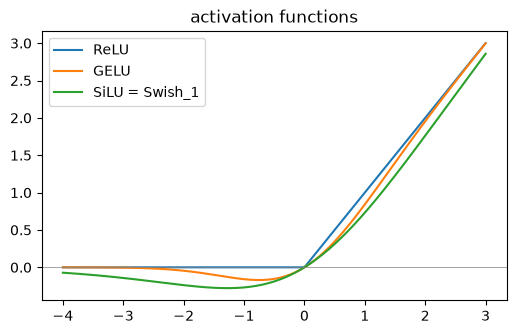

In [8]:
z = torch.linspace(-4, 3, 200)
plt.figure(figsize=(6, 3.5))
for name, f in (("ReLU", F.relu), ("GELU", F.gelu), ("SiLU = Swish_1", F.silu)): plt.plot(z, f(z), label=name)
plt.axhline(0, color="gray", lw=0.5); plt.legend(); plt.title("activation functions"); plt.show()

## 3. A GPT-2 block from raw weights
Load GPT-2 small. Rebuild block 5 from our `LayerNorm`, `MultiHeadAttention` and `MLP` with GPT-2's weights copied in, and compare with the output of the Hugging Face block. Hugging Face's `hidden_states[12]` is already after the final LayerNorm, so we rebuild the raw residual stream block by block.

In [9]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
tok = GPT2TokenizerFast.from_pretrained("gpt2")
gm = GPT2LMHeadModel.from_pretrained("gpt2").eval()
path = "data/tinyshakespeare.txt"
if not os.path.exists(path):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", path)
text = open(path).read()
enc = tok.encode(text[:100000]); T = 256
x = torch.tensor([enc[i * T:(i + 1) * T] for i in range(8)])
with torch.no_grad():
    H = [gm(x, output_hidden_states=True).hidden_states[0]]; upd = []
    for blk in gm.transformer.h:
        h0 = H[-1]; a = blk.attn(blk.ln_1(h0))[0]; h1 = h0 + a; m = blk.mlp(blk.ln_2(h1)); H.append(h1 + m)
        upd.append(((a[:, 1:].norm(dim=-1) / h0[:, 1:].norm(dim=-1)).mean().item(), (m[:, 1:].norm(dim=-1) / h1[:, 1:].norm(dim=-1)).mean().item()))
    logits = gm.lm_head(gm.transformer.ln_f(H[-1]))
print("rebuilt stream gives the model's logits:", torch.allclose(logits, gm(x).logits, atol=1e-3))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 4801.24it/s]


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (30645 > 1024). Running this sequence through the model will result in indexing errors


rebuilt stream gives the model's logits: True


In [10]:
l = 5; hb = gm.transformer.h[l]; d = 768
ln1, ln2, att, mlp = LayerNorm(d), LayerNorm(d), MultiHeadAttention(d, 12), MLP(d)
with torch.no_grad():
    for ours, theirs in ((ln1, hb.ln_1), (ln2, hb.ln_2)): ours.weight.copy_(theirs.weight); ours.bias.copy_(theirs.bias)
    att.qkv.weight.copy_(hb.attn.c_attn.weight.T); att.qkv.bias.copy_(hb.attn.c_attn.bias)      # GPT-2's Conv1D stores (in, out)
    att.proj.weight.copy_(hb.attn.c_proj.weight.T); att.proj.bias.copy_(hb.attn.c_proj.bias)
    mlp.fc.weight.copy_(hb.mlp.c_fc.weight.T); mlp.fc.bias.copy_(hb.mlp.c_fc.bias)
    mlp.proj.weight.copy_(hb.mlp.c_proj.weight.T); mlp.proj.bias.copy_(hb.mlp.c_proj.bias)
    h = H[l] + att(ln1(H[l]))                                       # x + Attn(LN(x))
    h = h + mlp(ln2(h))                                             # x + MLP(LN(x))
print("max |our block - GPT-2 block|:", (h - H[l + 1]).abs().max().item(), "  (stream values reach", round(H[l + 1].abs().max().item()), ")")

max |our block - GPT-2 block|: 1.9073486328125e-05   (stream values reach 2921 )


## 4. Inside GPT-2's residual stream
Norm of the stream after each block (token 0 separately), and how big each sublayer's write is relative to the stream it is added to.

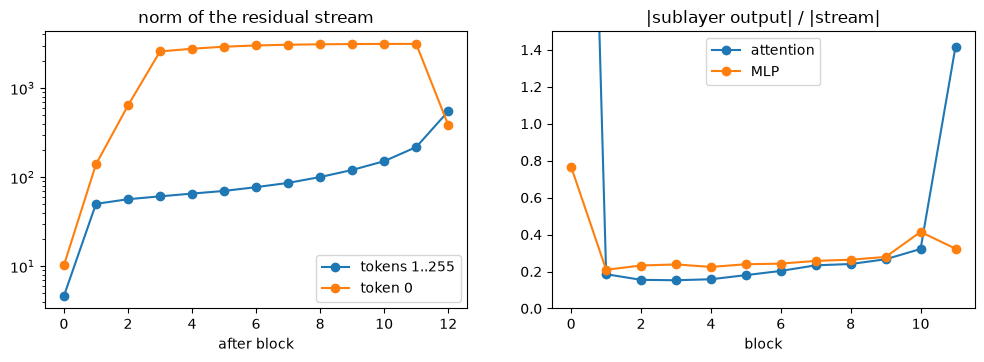

token 0, after block 6: largest dimensions [447, 138, 378] values [2899.0, 800.0, -67.0]
median |value| of the other tokens: 1.2721530199050903
mean / rms of a token vector (tokens 1..): [0.031, 0.009, 0.01, 0.009, 0.008, 0.008, 0.009, 0.009, 0.011, 0.01, 0.011, 0.022, 0.011]


In [11]:
rest = [h[:, 1:].norm(dim=-1).mean().item() for h in H]; first = [h[:, 0].norm(dim=-1).mean().item() for h in H]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].semilogy(rest, "o-", label="tokens 1..255"); ax[0].semilogy(first, "o-", label="token 0"); ax[0].set_xlabel("after block"); ax[0].set_title("norm of the residual stream"); ax[0].legend()
ax[1].plot([u[0] for u in upd], "o-", label="attention"); ax[1].plot([u[1] for u in upd], "o-", label="MLP"); ax[1].set_ylim(0, 1.5)
ax[1].set_xlabel("block"); ax[1].set_title("|sublayer output| / |stream|"); ax[1].legend(); plt.show()
mid = H[6][:, 0]; top = mid.abs().mean(0).topk(3)
print("token 0, after block 6: largest dimensions", top.indices.tolist(), "values", mid.mean(0)[top.indices].round().tolist())
print("median |value| of the other tokens:", H[6][:, 1:].abs().median().item())
print("mean / rms of a token vector (tokens 1..):", [round((h[:, 1:].mean(-1).abs() / h[:, 1:].pow(2).mean(-1).sqrt()).mean().item(), 3) for h in H])

**Logit lens** (nostalgebraist 2020): apply the final LayerNorm and the unembedding to the stream after block `l`, as if the model stopped there.

In [12]:
y = x[:, 1:]; top_final = logits[:, :-1].argmax(-1); res = []
with torch.no_grad():
    for l in range(13):
        lg = gm.lm_head(gm.transformer.ln_f(H[l]))[:, :-1]
        res.append((F.cross_entropy(lg.flatten(0, 1), y.flatten()).item(), (lg.argmax(-1) == top_final).float().mean().item()))
for l, (ls, ag) in enumerate(res): print(f"after block {l:2d}: loss {ls:6.2f}   top-1 same as final {ag:.2f}")

after block  0: loss  51.09   top-1 same as final 0.00
after block  1: loss  10.23   top-1 same as final 0.12
after block  2: loss   9.66   top-1 same as final 0.11
after block  3: loss   9.35   top-1 same as final 0.13
after block  4: loss   9.38   top-1 same as final 0.09
after block  5: loss   9.47   top-1 same as final 0.09
after block  6: loss   9.12   top-1 same as final 0.12
after block  7: loss   9.00   top-1 same as final 0.15
after block  8: loss   8.66   top-1 same as final 0.22
after block  9: loss   8.11   top-1 same as final 0.28
after block 10: loss   7.50   top-1 same as final 0.37
after block 11: loss   6.61   top-1 same as final 0.50
after block 12: loss   4.64   top-1 same as final 1.00


Swap every LayerNorm of GPT-2 for an RMSNorm (keep its gain and bias, drop only the mean subtraction). A model trained with LayerNorm has adapted to it, so this is a stress test, not how RMSNorm is used.

In [13]:
lns = [m for m in gm.modules() if isinstance(m, nn.LayerNorm)]; saved = [m.forward for m in lns]
for m_ in lns: m_.forward = (lambda mod: lambda h: h * torch.rsqrt(h.pow(2).mean(-1, keepdim=True) + mod.eps) * mod.weight + mod.bias)(m_)
with torch.no_grad(): lg2 = gm(x).logits
for m_, f in zip(lns, saved): m_.forward = f
print(f"loss with LayerNorm {res[-1][0]:.3f},  with RMSNorm {F.cross_entropy(lg2[:, :-1].flatten(0, 1), y.flatten()).item():.3f},  top-1 agreement {(lg2[:, :-1].argmax(-1) == top_final).float().mean():.2f}")

loss with LayerNorm 4.639,  with RMSNorm 4.747,  top-1 agreement 0.86


## 5. Data for the small models
TinyShakespeare characters, same 90/10 split as Modules 3 and 4.

In [14]:
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; V = len(chars)
ids = np.array([stoi[c] for c in text]); cut = int(0.9 * len(ids)); tr, te = ids[:cut], ids[cut:]
p = np.bincount(tr, minlength=V) / len(tr); unigram = float(-(p * np.log(p + 1e-12)).sum())
print(V, "characters;  unigram entropy (a model that ignores context):", round(unigram, 3))

65 characters;  unigram entropy (a model that ignores context): 3.309


## 6. Why residuals and pre-norm: 12-block models
Gradient norm of each block at initialisation, then training at a high learning rate (1e-2, Adam, no warmup, 400 steps). About 4 minutes.

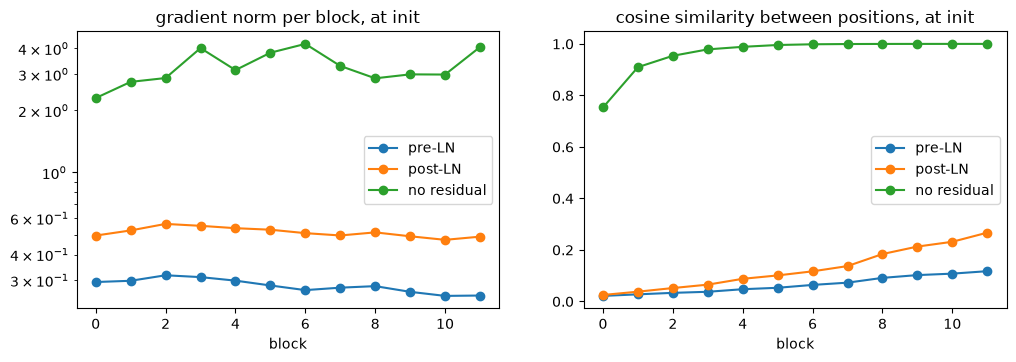

In [15]:
VARIANTS = {"pre-LN": dict(norm="ln", place="pre", ffn="gelu"), "post-LN": dict(norm="ln", place="post", ffn="gelu"),
            "no residual": dict(norm="ln", place="pre", ffn="gelu", residual=False)}
def deep(kw, seed=0):
    torch.manual_seed(seed); return GPT(V, 32, 64, 4, 12, **kw)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for n, kw in VARIANTS.items():
    ax[0].semilogy(grad_norm_per_block(deep(kw), tr), "o-", label=n)
    ax[1].plot(token_similarity_per_block(deep(kw), tr), "o-", label=n)
ax[0].set_title("gradient norm per block, at init"); ax[1].set_title("cosine similarity between positions, at init")
for a in ax: a.set_xlabel("block"); a.legend()
plt.show()

pre-LN       final train loss 2.046  (53s)


post-LN      final train loss 3.309  (52s)


no residual  final train loss 3.309  (53s)


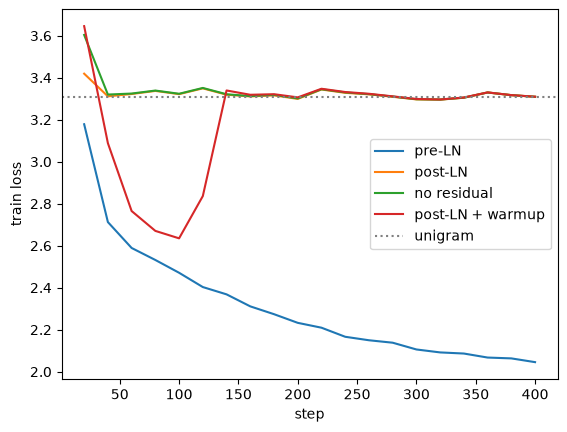

In [16]:
curves = {}
for n, kw in VARIANTS.items():
    t0 = time.time(); curves[n] = train(deep(kw), tr, steps=400, lr=1e-2, bs=32, log_every=20); print(f"{n:12s} final train loss {curves[n][-1]:.3f}  ({time.time()-t0:.0f}s)")
curves["post-LN + warmup"] = train(deep(VARIANTS["post-LN"]), tr, steps=400, lr=1e-2, bs=32, warmup=100, log_every=20)
for n, h in curves.items(): plt.plot(np.arange(1, len(h) + 1) * 20, h, label=n)
plt.axhline(unigram, ls=":", color="gray", label="unigram"); plt.xlabel("step"); plt.ylabel("train loss"); plt.legend(); plt.show()

## 7. From attention-only to a full block
Two blocks, d = 64, 4 heads, context 64, 2,000 Adam steps at 3e-3, scored like Module 4 (positions >= 8 of held-out windows). One seed here (the lesson's figure averages two). About 9 minutes.

In [17]:
ABL = {"attention only (Module 4)": dict(norm=None, ffn=None), "+ GELU MLP": dict(norm=None, ffn="gelu"),
       "+ pre-LayerNorm (GPT-2 block)": dict(norm="ln", ffn="gelu"), "RMSNorm + SwiGLU (Llama block)": dict(norm="rms", ffn="swiglu")}
models = {}
for n, kw in ABL.items():
    torch.manual_seed(0); m = GPT(V, 64, 64, 4, 2, **kw); t0 = time.time(); train(m, tr, steps=2000); models[n] = m
    print(f"{n:32s} params {sum(p.numel() for p in m.parameters()):7,}  train {evaluate(m, tr[:len(te)]):.3f}  held-out {evaluate(m, te):.3f}  ({time.time()-t0:.0f}s)")

attention only (Module 4)        params  45,761  train 1.833  held-out 1.957  (80s)


+ GELU MLP                       params 111,937  train 1.527  held-out 1.713  (132s)


+ pre-LayerNorm (GPT-2 block)    params 112,577  train 1.549  held-out 1.720  (167s)


RMSNorm + SwiGLU (Llama block)   params 111,361  train 1.511  held-out 1.701  (147s)


In [18]:
print(sample(models["RMSNorm + SwiGLU (Llama block)"], chars, stoi, "\n", 300, seed=1))



Can; this songuausel, that me, by my shall with a virtue,
And here, in with your all gainst hease:
They go puty or doin the noble siships at Ere
Besire your heard homan to the him.

CLAUDIO:
I say, by me not the dunhank only weizes:
Shall;
For to such was that not, he hunded such teem? it we, then,


## Exercises
1. **Where is the norm?** Without retraining, compute the RMS of the residual stream after each block of the trained pre-LN model of section 7 and compare with the norm of the input to each sublayer. Which one is controlled, and which one grows?
2. **Init scaling.** GPT-2 scales the weights of the layers that write into the residual stream (`att.proj`, the FFN's last matrix) by 1/sqrt(N), N the number of residual layers. Add this to `GPT.__init__` and redo the gradient-norm plot and the high-learning-rate curves of section 6 for post-LN and pre-LN. Does post-LN train now?
3. **GEGLU and ReGLU.** Change `F.silu` in `SwiGLU` to `F.gelu` and `F.relu`, and add a plain bilinear version (no activation). Train each in the setup of section 7. Are the differences larger than the seed-to-seed spread in the lesson's table?
4. **Parallel block.** Implement the PaLM / GPT-J block `x + Attn(Norm(x)) + FFN(Norm(x))` (one norm, both sublayers read the same input). Compare its loss with the serial block at 2 and at 6 blocks.
5. **Open-ended: depth vs width.** At a fixed budget of about 110k parameters, compare 2 blocks of d = 64 with 6 blocks of d = 40 and 1 block of d = 96 (pre-RMSNorm, SwiGLU). Plot held-out loss against training steps. Which wins early, and which late?
6. **Open-ended: massive activations.** In GPT-2, set dimension 447 of token 0's residual stream to 0 after block 3 (use a forward hook) and measure the loss. Then do the same for a random dimension. What happens to the attention weights on token 0 (load the model with `attn_implementation="eager"` to get them)?